# ML for Digit Recognition
    
    We have seen in the previous notebook some analysis, techniques and methodology to address a problem involving images for predictive analytics. In this notebook we break away from the intro and dive into how all the machine learning algorithms could help us in digit recognition

## Getting the data ready

In [1]:
from keras.datasets import mnist
from matplotlib import pyplot
(X_train, y_train), (X_test, y_test) = mnist.load_data()
from keras.utils import np_utils
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
pd.set_option('display.max_columns', 100) # Show all columns when looking at dataframe
import warnings
warnings.filterwarnings('ignore') # remove warnings from the notebook

Using TensorFlow backend.


In [2]:
# flatten 28*28 images to a 784 vector for each image
num_pixels = X_train.shape[1] * X_train.shape[2]
X_train = X_train.reshape(X_train.shape[0], num_pixels).astype( 'float32' )
X_test = X_test.reshape(X_test.shape[0], num_pixels).astype( 'float32' )
# normalize inputs from 0-255 to 0-1
X_train_scaled = X_train / 255
X_test_scaled = X_test / 255
# one hot encode outputs
y_train_enc = np_utils.to_categorical(y_train)
y_test_enc = np_utils.to_categorical(y_test)
num_classes = y_test_enc.shape[1]

# Modeling

To start with modeling I will show you how to use scikit-learn to do machine learning classification on the MNIST database of handwritten digits. We'll use and discuss the following methods:

- K-Nearest Neighbors
- Random Forest
- Linear SVC

Let's just get going!!

## K-Nearest Neighbors

*K Nearest Neighbour is a simple algorithm that stores all the available cases and classifies the new data or case based on a similarity measure. It is mostly used to classifies a data point based on how its neighbours are classified.*


**Pros: High accuracy, insensitive to outliers, no assumptions about data**

**Cons: Computationally expensive, requires a lot of memory**

**Works with: Numeric values, nominal values**

In [3]:
from sklearn.neighbors import KNeighborsClassifier
clf = KNeighborsClassifier()
# Training Models..
clf.fit(X_train_scaled, y_train)

KNeighborsClassifier(algorithm='auto', leaf_size=30, metric='minkowski',
                     metric_params=None, n_jobs=None, n_neighbors=5, p=2,
                     weights='uniform')

In [4]:
#Compute predictions
y_pred = clf.predict(X_test_scaled)

In [5]:
#Calculating accuracy using sklearn matrix 
from sklearn.metrics import confusion_matrix, accuracy_score
acc = accuracy_score(y_test, y_pred)
acc

0.9688

In [6]:
results = pd.DataFrame([['K-Nearest Neighbors', f"{acc*100} %"]], columns = ['Model', 'Accuracy'])
results 

,Model,Accuracy
0,K-Nearest Neighbors,96.88 %


*Whoa!! A simple model like K-Nearest Neighbors is giving us 96.88 % thats a great insight , Let get the confusion matrix and classification report for the same*

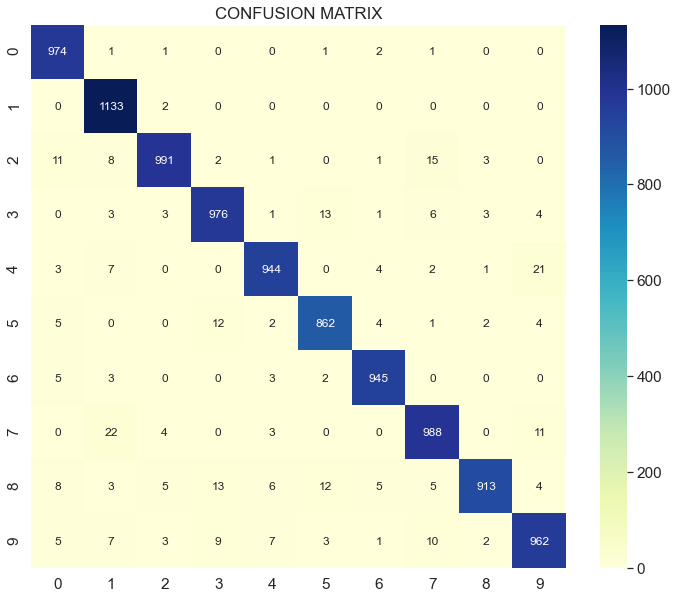

In [7]:
df_cm = pd.DataFrame(confusion_matrix(y_test, y_pred), range(10),
                  range(10))
plt.figure(figsize = (12,10))
sns.set(font_scale=1.4) #for label size
sns.heatmap(df_cm, annot=True, annot_kws={"size": 12}, cmap="YlGnBu", fmt='g').set_title("CONFUSION MATRIX"); # font size

In [8]:
from sklearn.metrics import classification_report
print("CLASSIFICATION REPORT OF K-NEAREST NEIGHBOURS")
print()
print(classification_report(y_test, y_pred))

CLASSIFICATION REPORT OF K-NEAREST NEIGHBOURS

              precision    recall  f1-score   support

           0       0.96      0.99      0.98       980
           1       0.95      1.00      0.98      1135
           2       0.98      0.96      0.97      1032
           3       0.96      0.97      0.97      1010
           4       0.98      0.96      0.97       982
           5       0.97      0.97      0.97       892
           6       0.98      0.99      0.98       958
           7       0.96      0.96      0.96      1028
           8       0.99      0.94      0.96       974
           9       0.96      0.95      0.95      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



## Linear Support Vector Classification




*A Support Vector Machine (SVM) is a discriminative classifier formally defined by a separating hyperplane. In other words, given labeled training data (supervised learning), the algorithm outputs an optimal hyperplane which categorizes new examples. In two dimentional space this hyperplane is a line dividing a plane in two parts where in each class lay in either side.*


**Pros:  Accuracy , Works well on smaller cleaner datasets, It can be more efficient because it uses a subset of training points**

**Cons: Isn’t suited to larger datasets as the training time with SVMs can be high, Less effective on noisier datasets with overlapping classes**


In [9]:
from sklearn.svm import SVC
clf = SVC(random_state = 0, kernel = 'linear')
# Training model...
clf.fit(X_train_scaled, y_train)

SVC(C=1.0, break_ties=False, cache_size=200, class_weight=None, coef0=0.0,
    decision_function_shape='ovr', degree=3, gamma='scale', kernel='linear',
    max_iter=-1, probability=False, random_state=0, shrinking=True, tol=0.001,
    verbose=False)

In [10]:
#Compute predictions
y_pred = clf.predict(X_test_scaled)

In [11]:
#Calculating accuracy using sklearn matrix 
from sklearn.metrics import confusion_matrix, accuracy_score
acc = accuracy_score(y_test, y_pred)
acc

0.9404

In [12]:
model_results = pd.DataFrame([['SVC (Linear)', f'{acc*100} %']], columns = ['Model', 'Accuracy'])
results = results.append(model_results, ignore_index = True)
results

,Model,Accuracy
0,K-Nearest Neighbors,96.88 %
1,SVC (Linear),94.04 %


*Accuracy is a bit lower than K- Nearest Neighbours but there is trade off  SVM is Faster than K-Nearest Neighbours.Lets get confusion Matrix for the same.*

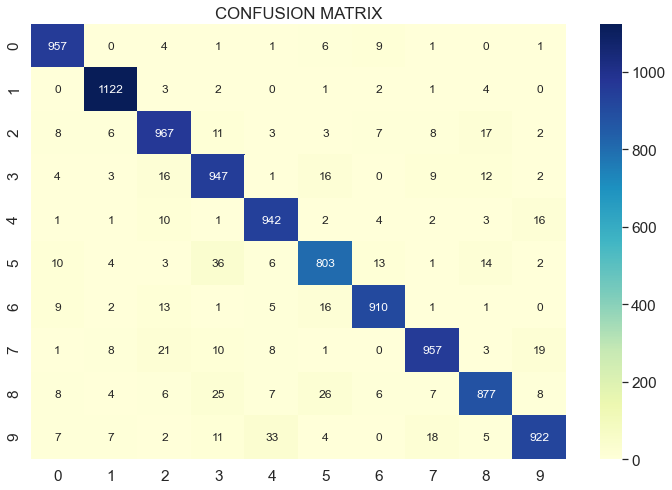

In [13]:
# Dataframe for Confusion Matrix
df_cm = pd.DataFrame(confusion_matrix(y_test, y_pred), range(10),range(10))
# Plotting the confusion matrix
plt.figure(figsize = (12,8))
sns.set(font_scale=1.4) #for label size
sns.heatmap(df_cm, annot=True, annot_kws={"size": 12}, cmap="YlGnBu", fmt='g').set_title("CONFUSION MATRIX"); # font size

In [14]:
from sklearn.metrics import classification_report
print("CLASSIFICATION REPORT OF LINEAR SUPPORT VECTOR CLASSIFIER")
print()
print(classification_report(y_test, y_pred))

CLASSIFICATION REPORT OF LINEAR SUPPORT VECTOR CLASSIFIER

              precision    recall  f1-score   support

           0       0.95      0.98      0.96       980
           1       0.97      0.99      0.98      1135
           2       0.93      0.94      0.93      1032
           3       0.91      0.94      0.92      1010
           4       0.94      0.96      0.95       982
           5       0.91      0.90      0.91       892
           6       0.96      0.95      0.95       958
           7       0.95      0.93      0.94      1028
           8       0.94      0.90      0.92       974
           9       0.95      0.91      0.93      1009

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



*Other than Linear Kernel for SVM try Exploring other kernels ‘poly’, ‘rbf’, ‘sigmoid’, Let us know in the discussion forums. Or in Slack channel, The following code snippet will help you do that.*

from sklearn.svm import SVC

from sklearn.model_selection import cross_val_score

svm = SVC()

parameters = {'kernel':('poly', 'rbf', 'sigmoid'), 'C':(1,0.25,0.5,0.75),'gamma': (1,2,3,'auto'),'decision_function_shape':('ovo','ovr'),'shrinking':(True,False)}

clf = GridSearchCV(svm, parameters)

clf.fit(X_train_scaled,y_train)

print("accuracy:"+str(np.average(cross_val_score(clf, X_train, Y, scoring='accuracy'))))

**Now lets try out one of ensemble techniques, Random Forest Classifier**

## Random Forest Classification

*Random Forest is an ensemble of Decision Trees, generally trained via the bagging method (or sometimes pasting), typically with max_samples set to the size of the training set.*

*The Random Forest algorithm introduces extra randomness when growing trees; instead of searching for the very best feature when splitting a node , it searches for the best feature among a random subset of features. This results in a greater tree diversity, which (once again) trades a higher bias for a lower variance, generally yielding an overall better model.*


**Pros :**
- The predictive performance can compete with the best supervised learning algorithms
- They provide a reliable feature importance estimate
- They offer efficient estimates of the test error without incurring the cost of repeated model training associated with cross-validation

**Cons :**
- An ensemble model is inherently less interpretable than an individual decision tree
- Training a large number of deep trees can have high computational costs (but can be parallelized) and use a lot of memory
- Predictions are slower, which may create challenges for applications that require low latency .



In [15]:
from sklearn.ensemble import RandomForestClassifier
# Training Model.....
clf = RandomForestClassifier()
clf.fit(X_train_scaled, y_train)

RandomForestClassifier(bootstrap=True, ccp_alpha=0.0, class_weight=None,
                       criterion='gini', max_depth=None, max_features='auto',
                       max_leaf_nodes=None, max_samples=None,
                       min_impurity_decrease=0.0, min_impurity_split=None,
                       min_samples_leaf=1, min_samples_split=2,
                       min_weight_fraction_leaf=0.0, n_estimators=100,
                       n_jobs=None, oob_score=False, random_state=None,
                       verbose=0, warm_start=False)

In [16]:
#Compute predictions
y_pred = clf.predict(X_test_scaled)

In [17]:
#Calculating accuracy using sklearn matrix 
from sklearn.metrics import confusion_matrix, accuracy_score
acc = accuracy_score(y_test, y_pred)
acc

0.971

*Lets quickly do a K-fold cross valiadtion on the training set with 10 folds*

In [18]:
from sklearn.model_selection import cross_val_score
scores= cross_val_score(clf, X_train_scaled, y_train, scoring= "accuracy", cv=10)

In [19]:
def display_scores(scores):
    print("Scores: ", scores)
    print("Mean: ", scores.mean())
    print("Standard deviation: ", scores.std())

display_scores(scores)

Scores:  [0.972      0.96716667 0.96533333 0.96733333 0.9645     0.96616667
 0.96666667 0.96416667 0.96666667 0.97733333]
Mean:  0.9677333333333333
Standard deviation:  0.0038014617071741243


*There is not much deviation the model, this model looks fine but still this can be improved after fine tuning its hyperparameters.Which we will discuss next*

In [20]:
model_results = pd.DataFrame([['Random Forest Classifier', f'{acc*100} %']], columns = ['Model', 'Accuracy'])
results = results.append(model_results, ignore_index = True)
results

,Model,Accuracy
0,K-Nearest Neighbors,96.88 %
1,SVC (Linear),94.04 %
2,Random Forest Classifier,97.1 %


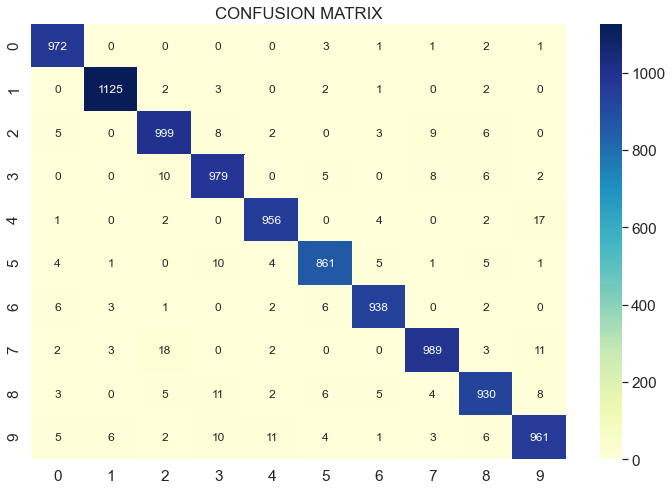

In [21]:
# Dataframe for Confusion Matrix
df_cm = pd.DataFrame(confusion_matrix(y_test, y_pred), range(10),range(10))
# Plotting the confusion matrix
plt.figure(figsize = (12,8))
sns.set(font_scale=1.4) #for label size
sns.heatmap(df_cm, annot=True, annot_kws={"size": 12}, cmap="YlGnBu", fmt='g').set_title("CONFUSION MATRIX"); # font size

In [22]:
from sklearn.metrics import classification_report
print("CLASSIFICATION REPORT OF RANDOM FOREST CLASSIFIER")
print()
print(classification_report(y_test, y_pred))

CLASSIFICATION REPORT OF RANDOM FOREST CLASSIFIER

              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.99      0.99      0.99      1135
           2       0.96      0.97      0.96      1032
           3       0.96      0.97      0.96      1010
           4       0.98      0.97      0.98       982
           5       0.97      0.97      0.97       892
           6       0.98      0.98      0.98       958
           7       0.97      0.96      0.97      1028
           8       0.96      0.95      0.96       974
           9       0.96      0.95      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



**Before jumping on to state of the art Neural Networks, Lets try fine tuining the hyperparameters of Random Forest**

### Hyperparameters that we will be tuning.


**n_estimators**

*n_estimators represents the number of trees in the forest. Usually the higher the number of trees the better to learn the data. However, adding a lot of trees can slow down the training process considerably, therefore we do a parameter search to find the sweet spot.*

**max_depth**

*max_depth represents the depth of each tree in the forest. The deeper the tree, the more splits it has and it captures more information about the data. We fit each decision tree with depths ranging from 1 to 32 and plot the training and test errors.*

**min_samples_split**

*min_samples_split represents the minimum number of samples required to split an internal node. This can vary between considering at least one sample at each node to considering all of the samples at each node. When we increase this parameter, each tree in the forest becomes more constrained as it has to consider more samples at each node. Here we will vary the parameter from 10% to 100% of the samples**

**min_samples_leaf**

*min_samples_leaf is The minimum number of samples required to be at a leaf node. This parameter is similar to min_samples_splits, however, this describe the minimum number of samples of samples at the leafs, the base of the tree.*

**max_features**

*max_features represents the number of features to consider when looking for the best split.*

*Below code snipet demonstates how to Tune Hyperparamets using Grid search for RandomForestClassifier*
*Try diffrent values of these hyperparameters and get back to us with us  the best estimator.*

In [25]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'max_depth': [100, 110],
    'max_features': [500, 700],
    'min_samples_leaf': [3, 4, 5],
    'min_samples_split': [8, 10, 12],
    'n_estimators': [300, 700]
}
rf = RandomForestClassifier()
grid_search = GridSearchCV(rf, param_grid, cv=3,
                           scoring='accuracy', return_train_score=True, verbose = 1, n_jobs= -1)
grid_search.fit(X_train_scaled, y_train)
print("Best Parameters: ", grid_search.best_params_)
print("Best Model: ", grid_search.best_estimator_)
# Final Model
final_RFC = grid_search.best_estimator_
final_RFC_predictions = final_model.predict(X_test)
acc = accuracy_score(y_test, final_RFC_predictions)
print("Accuracy: ", acc)

Fitting 3 folds for each of 72 candidates, totalling 216 fits


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.


ValueError: buffer source array is read-only